In [1]:
from transformers import AutoTokenizer
import re
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
import numpy as np
from tqdm import tqdm
import os

/user/i.elcoroalberdi/u25035/MASTER/thesis/.venv/lib/python3.11/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
model_name = "DeepEsp/gpt2-spanish"
tokenizer_old = AutoTokenizer.from_pretrained(model_name)
ds_euscrawl = load_dataset("HiTZ/latxa-corpus-v1.1", 'euscrawl-v1.1')
# take the first 50,000 sentences from the train split
sentences = ds_euscrawl["train"]["text"][:50000]

In [3]:
tok_path = "/mnt/vast-react/home/i.elcoroalberdi/u25035/MASTER/thesis/basque_tokenizer_50257"
tokenizer_new = AutoTokenizer.from_pretrained(tok_path)

In [4]:
# Vocabulary size
print("Vocabulary size:", tokenizer_old.vocab_size)
print("Vocabulary size (new):", tokenizer_new.vocab_size)

Vocabulary size: 50257
Vocabulary size (new): 50257


In [5]:
text = "Euskara adimen arttifizialera iritsi da!"

# Encode text → token IDs
token_ids = tokenizer_old.encode(text)
print("Token IDs:", token_ids)

# Decode back to text
decoded_text = tokenizer_old.decode(token_ids)
print("Decoded text:", decoded_text)

Token IDs: [46, 11990, 531, 3958, 1966, 2344, 10707, 439, 1354, 437, 464, 12913, 676, 1167, 10]
Decoded text: Euskara adimen arttifizialera iritsi da!


BASIC TOKENIZATION STATISTICS

In [6]:
# Average tokens per word and per sentence

def avg_tokens_per_word(sentences, tokenizer):
    token_counts = []
    word_counts = []

    for sent in sentences:
        tokens = tokenizer.tokenize(sent)
        words = sent.split()

        token_counts.append(len(tokens))
        word_counts.append(len(words))

    avg_tokens_word = sum(token_counts) / sum(word_counts)
    return avg_tokens_word

In [7]:
avg_tokens_word = avg_tokens_per_word(sentences, tokenizer_old)
print(f"Average tokens per word: {avg_tokens_word:.2f}")

Average tokens per word: 3.06


In [8]:
avg_tokens_word = avg_tokens_per_word(sentences, tokenizer_new)
print(f"Average tokens per word: {avg_tokens_word:.2f}")

Average tokens per word: 2.42


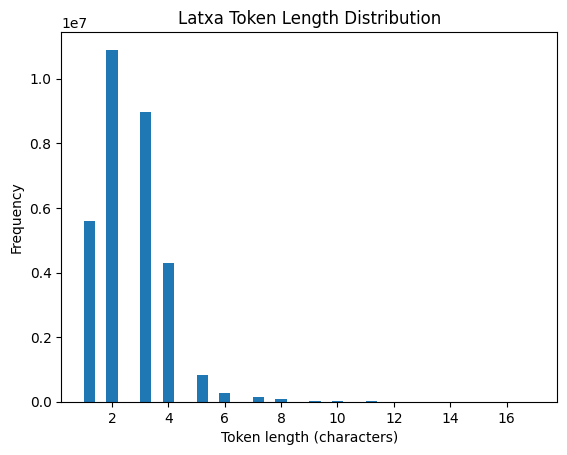

In [9]:
# Token length distribution

all_tokens = []
for sent in sentences:
    t = tokenizer_old.tokenize(sent)
    all_tokens.extend(t)

# compute token lengths
token_lengths = [len(tok.replace("▁", "")) for tok in all_tokens]

plt.hist(token_lengths, bins=40)
plt.xlabel("Token length (characters)")
plt.ylabel("Frequency")
plt.title("Latxa Token Length Distribution")
plt.show()

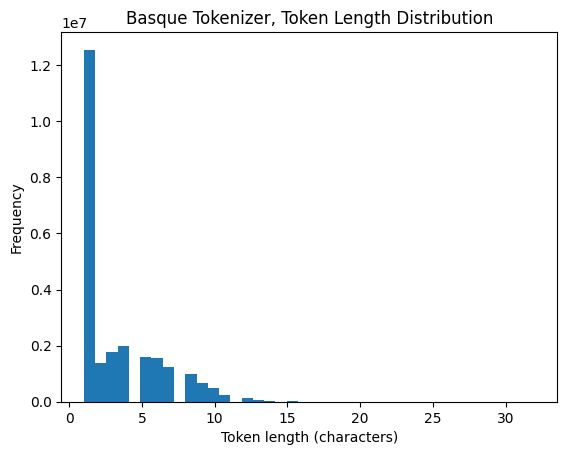

In [4]:
# Token length distribution

all_tokens = []
for sent in sentences:
    t = tokenizer_new.tokenize(sent)
    all_tokens.extend(t)

# compute token lengths
token_lengths = [len(tok.replace("▁", "")) for tok in all_tokens]

plt.hist(token_lengths, bins=40)
plt.xlabel("Token length (characters)")
plt.ylabel("Frequency")
plt.title("Basque Tokenizer, Token Length Distribution")
plt.show()

In [5]:
# Word coverage analysis

def word_coverage(tokenizer, sentences, max_check=30000):    
    total = 0
    single = 0
    for sent in sentences[:max_check]:
        words = sent.split()
        for w in words:
            ids = tokenizer.encode(w, add_special_tokens=False)
            ids = [i for i in ids if i not in tokenizer.all_special_ids]
            total += 1
            if len(ids) == 1:
                single += 1

    return {
        "total": total,
        "single": single
    }

In [6]:
wc = word_coverage(tokenizer_old, sentences)
print(f"Single-token word coverage: {wc['single']}/{wc['total']} ({(wc['single']/wc['total'])*100:.2f}%)")

Single-token word coverage: 868799/6040519 (14.38%)


In [7]:
wc = word_coverage(tokenizer_new, sentences)
print(f"Single-token word coverage: {wc['single']}/{wc['total']} ({(wc['single']/wc['total'])*100:.2f}%)")

Single-token word coverage: 4099191/6040519 (67.86%)


In [31]:
# Most common subwords

subword_counts = Counter()

for sent in sentences:
    tokens = latxa_tokenizer.tokenize(sent)
    subword_counts.update(tokens)

# show most common subwords
for token, count in subword_counts.most_common(30):
    print(f"{token}: {count}")

a: 925826
,: 897237
.: 685129
an: 678140
<0x0A>: 622992
ak: 532591
▁et: 441600
ko: 440448
en: 390349
▁b: 322206
▁d: 320535
u: 312059
k: 301472
z: 287452
o: 287225
▁z: 279848
ik: 272644
ako: 270351
ar: 263712
at: 239945
▁: 229734
0: 212259
et: 198610
▁g: 196192
▁e: 192771
i: 186542
ze: 181178
▁du: 180060
ra: 178761
▁da: 177968


SPECIAL TOKENS

In [32]:
# Special tokens (e.g., padding, unknown, BOS, EOS)
print("Special tokens:", tokenizer.special_tokens_map)

# Example: IDs of special tokens
print("Special token IDs:", {k: tokenizer.convert_tokens_to_ids(v) 
                             for k,v in tokenizer.special_tokens_map.items()})


NameError: name 'tokenizer' is not defined

In [33]:
def analyze_special_tokens(tokenizer, texts, max_texts=20000):
    special = set(tokenizer.all_special_ids)
    token_counter = Counter()
    total_tokens = 0

    for text in tqdm(texts[:max_texts]):
        encoding = tokenizer(text, add_special_tokens=True)
        ids = encoding["input_ids"]
        
        total_tokens += len(ids)
        token_counter.update(ids)

    special_counts = {
        tokenizer.convert_ids_to_tokens(tid): token_counter[tid]
        for tid in tokenizer.all_special_ids
    }
    return {
        "special_token_counts": special_counts,
        "total_tokens": total_tokens
    }

sentences_test = ds_euscrawl['test']['text'][:20000]
results = analyze_special_tokens(latxa_tokenizer, sentences_test)
print("Special token counts:", results["special_token_counts"])
print("Total tokens analyzed:", results["total_tokens"])


100%|██████████| 17736/17736 [00:16<00:00, 1048.62it/s]

Special token counts: {'<s>': 17736, '</s>': 0, '<unk>': 0}
Total tokens analyzed: 11284287


Latxa’s tokenizer:
- is extremely subword-heavy
- rarely encodes whole Basque words as a single token (7.59%)
- but it still uses valid subwords → "unk" is never needed

TOKENIZATION CONSISTENCY

In [8]:
families = {
    "etxe (house)": ["etxe", "etxea", "etxeak", "etxeko", "etxeetako", "etxearen",
                    "etxeen", "etxean","etxeetan", "etxetik", "etxeetatik", "etxera",
                    "etxeetara", "etxerantz", "etxeetarantz"],
    "eskola (school)": ["eskola", "eskolak", "eskolako", "eskoletako", "eskolaren",
                       "eskolen", "eskolan", "eskoletan", "eskolatik", "eskoletatik",
                       "eskolara", "eskoletara", "eskolarantz", "eskoletarantz"],
    "neska (girl)": ["neska", "neskak", "neskek", "neskaren", "nesken", "neskari",
                     "neskei", "neskarekin", "neskekin", "neskarengana", "neskengana"],
    "ume (kid)": ["ume", "umea", "umeak", "umeek", "umearen", "umeen", "umeari", 
                  "umeei", "umearekin", "umeekin", "umearengana", "umeengana"],
    "osasun (health)": ["osasun-zerbitzu", "osasun-sistema", 
                        "osasun-politika", "osasun-langile", "osasun-zentro", 
                        "osasun-etxe", "osasun-krisi", "osasun-arazo"]
}

def analyze_family(words, tokenizer):
    print("\n=== Morphological Family ===")
    for w in words:
        tokens = tokenizer.tokenize(w)
        print(f"{w:<15} → {tokens}")


In [9]:
for family, words in families.items():
    print(f"\n############################")
    print(f"### {family}")
    print("############################")
    analyze_family(words, tokenizer_old)


############################
### etxe (house)
############################

=== Morphological Family ===
etxe            → ['et', 'xe']
etxea           → ['et', 'x', 'ea']
etxeak          → ['et', 'x', 'ea', 'k']
etxeko          → ['et', 'xe', 'ko']
etxeetako       → ['et', 'xe', 'eta', 'ko']
etxearen        → ['et', 'x', 'ear', 'en']
etxeen          → ['et', 'xe', 'en']
etxean          → ['et', 'xe', 'an']
etxeetan        → ['et', 'xe', 'etan']
etxetik         → ['et', 'xe', 'tik']
etxeetatik      → ['et', 'xe', 'eta', 'tik']
etxera          → ['et', 'x', 'era']
etxeetara       → ['et', 'xe', 'et', 'ara']
etxerantz       → ['et', 'x', 'er', 'ant', 'z']
etxeetarantz    → ['et', 'x', 'ee', 'tar', 'ant', 'z']

############################
### eskola (school)
############################

=== Morphological Family ===
eskola          → ['es', 'ko', 'la']
eskolak         → ['es', 'ko', 'lak']
eskolako        → ['es', 'ko', 'la', 'ko']
eskoletako      → ['es', 'ko', 'leta', 'ko']
eskolaren 

In [10]:
for family, words in families.items():
    print(f"\n############################")
    print(f"### {family}")
    print("############################")
    analyze_family(words, tokenizer_new)


############################
### etxe (house)
############################

=== Morphological Family ===
etxe            → ['etxe']
etxea           → ['etxea']
etxeak          → ['etxeak']
etxeko          → ['etxeko']
etxeetako       → ['etxeetako']
etxearen        → ['etxearen']
etxeen          → ['etxeen']
etxean          → ['etxean']
etxeetan        → ['etxeetan']
etxetik         → ['etxetik']
etxeetatik      → ['etxeetatik']
etxera          → ['etxera']
etxeetara       → ['etxeetara']
etxerantz       → ['etx', 'erantz']
etxeetarantz    → ['etxe', 'etarantz']

############################
### eskola (school)
############################

=== Morphological Family ===
eskola          → ['eskola']
eskolak         → ['eskolak']
eskolako        → ['eskolako']
eskoletako      → ['eskoletako']
eskolaren       → ['eskolaren']
eskolen         → ['eskolen']
eskolan         → ['eskolan']
eskoletan       → ['eskoletan']
eskolatik       → ['eskolatik']
eskoletatik     → ['eskol', 'etatik']
esko

What we can observe:
1. Stem inconsistency: all four stem words are split differently depending on the suffix they have attached.
2. Suffix inconsistency: suffixes like -ko (from where), -ren (whose), -ri (to who) are not split consistently.
3. Compound words: compound words in Basque are often hyphenated, and the splitting in this case is quite consistent.

Average Rank

100%|██████████| 50000/50000 [00:44<00:00, 1113.40it/s]


Total tokens analyzed: 32530950
Average Rank: 8693.781218070792
Median Rank: 1997.0

Percentiles:
10th percentile: 285.0
25th percentile: 446.0
50th percentile: 1997.0
75th percentile: 14737.0
90th percentile: 29889.0
95th percentile: 29900.0


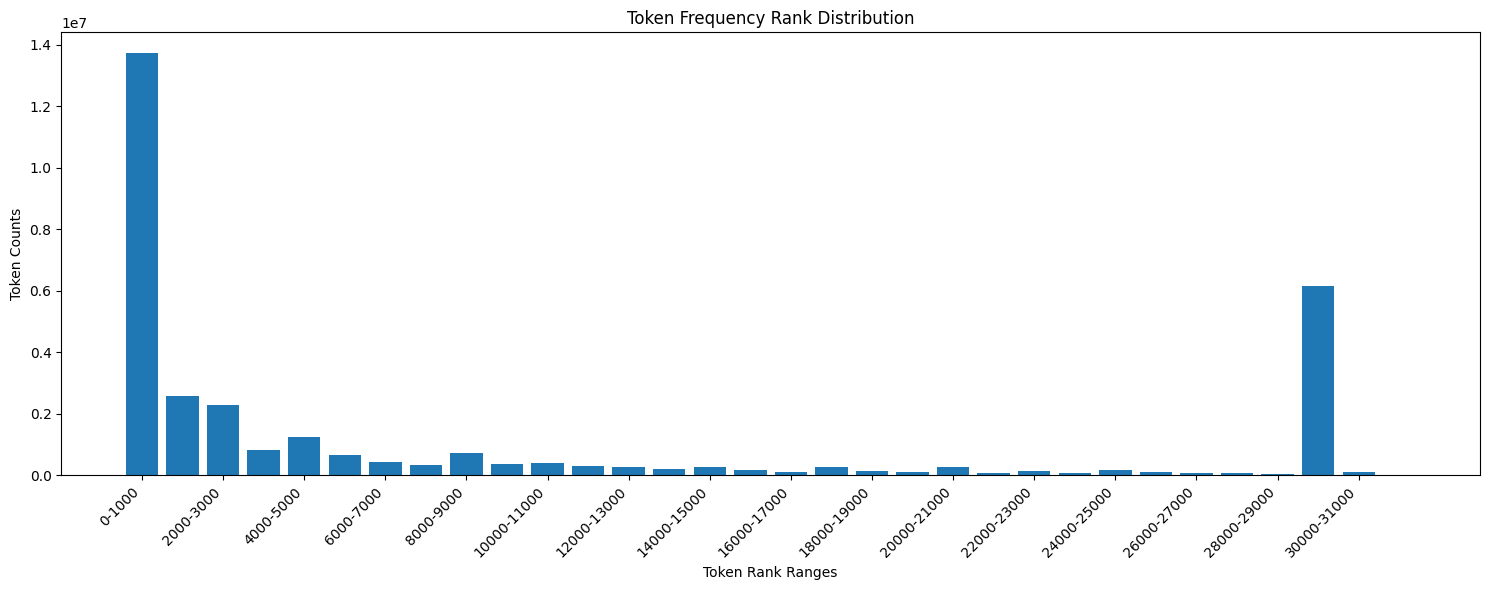

In [18]:
# Token frequency rank analysis

token_to_rank = {tok: idx for tok, idx in tokenizer.get_vocab().items()} 

ranks = []
for line in tqdm(sentences):
    token_ids = tokenizer.encode(line, add_special_tokens=False)
    for tid in token_ids:
        tok = tokenizer.convert_ids_to_tokens(tid)
        if tok in token_to_rank:
            ranks.append(token_to_rank[tok])
ranks = np.array(ranks)

print("Total tokens analyzed:", len(ranks))
print("Average Rank:", ranks.mean())
print("Median Rank:", np.median(ranks))
print("\nPercentiles:")
for p in [10, 25, 50, 75, 90, 95]:
    print(f"{p}th percentile:", np.percentile(ranks, p))


bins = list(range(0, 32001, 1000))
hist = np.histogram(ranks, bins=bins)

# Create bar plot
plt.figure(figsize=(15,6))  # make it wider
plt.bar(range(len(hist[0])), hist[0])

# Use tick labels for every 2nd or 5th bin
tick_positions = range(0, len(bins)-1, 2)  # change 2 → 5 if too crowded
tick_labels = [f"{b1}-{b2}" for b1, b2 in zip(bins[:-1], bins[1:])]
plt.xticks(tick_positions, [tick_labels[i] for i in tick_positions], rotation=45, ha='right')

plt.xlabel("Token Rank Ranges")
plt.ylabel("Token Counts")
plt.title("Token Frequency Rank Distribution")
plt.tight_layout()  # prevent cutting off labels
plt.show()

In [19]:
# Get all subwords in the vocabulary
vocab = list(tokenizer.get_vocab().keys())

# Typical Basque patterns
basque_patterns = [
    r"tx", r"tz", r"ts", r"dd", r"tt", r"rr", r"k$", r"n$", r"ko$", r"ren$", r"etan$"
]

# Typical English patterns
english_patterns = [
    r"ing$", r"tion$", r"th", r"sh", r"ch", r"ck", r"ed$", r"ly$", r"pre", r"com", r"un", r"re", r"w", r"c", r"tch", r"wr", r"with", r"y"
]

def classify_token(token):
    is_basque = any(re.search(p, token) for p in basque_patterns)
    is_english = any(re.search(p, token) for p in english_patterns)
    return is_basque, is_english

basque_tokens = []
english_tokens = []
shared = []
other = []

for tok in vocab:
    is_basque, is_english = classify_token(tok)
    if is_basque and is_english:
        shared.append(tok)
    elif is_basque:
        basque_tokens.append(tok)
    elif is_english:
        english_tokens.append(tok)
    else:
        other.append(tok)

print("Total vocab size:", len(vocab))
print("Basque-like subwords:", len(basque_tokens))
print("English-like subwords:", len(english_tokens))
print("Shared Basque+English patterns:", len(shared))
print("Other / Neutral subwords:", len(other))

# show examples
print("\n### Example Basque-like subwords")
print(basque_tokens[:40])

print("\n### Example English-like subwords")
print(english_tokens[:40])

print("\n### Example shared-pattern subwords")
print(shared[:40])


Total vocab size: 32000
Basque-like subwords: 2057
English-like subwords: 8137
Shared Basque+English patterns: 1347
Other / Neutral subwords: 20459

### Example Basque-like subwords
['letter', '▁Gemeinden', '▁Martín', 'bern', '▁Hudson', '▁phen', '▁Seattle', '▁attra', 'lein', 'uments', 'lán', 'alen', '▁seats', 'uits', 'án', '▁txt', '▁Genomsnittlig', '▁torn', 'tn', '▁Jak', 'ultats', 'fatt', '▁Sen', 'ulsion', '▁Kon', 'tan', 'avan', '▁settlement', 'urr', 'addClass', '▁Lion', '▁ern', '▁Return', '▁horn', 'eben', 'eston', 'Open', 'omon', 'tt', '▁Tan']

### Example English-like subwords
['▁Gary', '▁Ubuntu', '▁chi', '▁supported', 'acia', 'ring', '▁regnig', 'Descriptor', '▁Championship', '▁Pref', 'âtre', '▁views', 'enced', '▁ry', '▁chrome', '▁twice', '▁warning', '▁painted', 'ischer', '▁wicht', 'frent', 'atre', 'nach', '▁Having', 'bare', '▁Property', '▁withdraw', 'yond', 'bury', 'iance', '▁directions', '▁apare', '▁classic', 'Types', '▁höch', 'teilung', 'clo', '▁communic', 'gc', 'ptic']

### Examp

In [3]:
def measure_vocab_usage(tokenizer, sentences):
    vocab_size = len(tokenizer.get_vocab())
    used_token_ids = set()
    
    for sent in sentences:
        token_ids = tokenizer.encode(sent, add_special_tokens=True)
        used_token_ids.update(token_ids)
    
    num_used = len(used_token_ids)
    usage_percentage = (num_used / vocab_size) * 100
    
    return {
        'vocab_size': vocab_size,
        'used_tokens': num_used,
        'unused_tokens': vocab_size - num_used,
        'usage_percentage': usage_percentage
    }

In [5]:
sentences = ds_euscrawl['train']['text'][:50000]
stats_latxa = measure_vocab_usage(latxa_tokenizer, sentences)
print("Latxa Tokenizer Vocabulary Usage Statistics:")
for k, v in stats_latxa.items():
    print(f"{k}: {v}")

Latxa Tokenizer Vocabulary Usage Statistics:
vocab_size: 32000
used_tokens: 15692
unused_tokens: 16308
usage_percentage: 49.0375


# New tokenizer

In [6]:
tokenizer_dir = "../latxa7b_basque_aligned_250k"
tokenizer_new = AutoTokenizer.from_pretrained(tokenizer_dir, use_fast=False)
print("Loaded tokenizer from", tokenizer_dir)

Loaded tokenizer from ../latxa7b_basque_aligned_250k


In [37]:
sentences = ds_euscrawl['train']['text'][:50000]
avg_tokens_word = avg_tokens_per_word(sentences, tokenizer_new)
print(f"Average tokens per word: {avg_tokens_word:.2f}")

Average tokens per word: 1.72


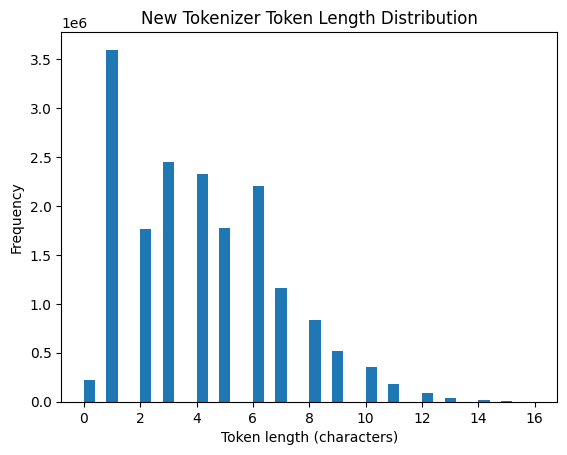

In [ ]:
# Token length distribution

all_tokens = []
for sent in sentences:
    t = tokenizer_new.tokenize(sent)
    all_tokens.extend(t)

# compute token lengths
token_lengths = [len(tok.replace("▁", "")) for tok in all_tokens]

plt.hist(token_lengths, bins=40)
plt.xlabel("Token length (characters)")
plt.ylabel("Frequency")
plt.title("New Tokenizer Token Length Distribution")
plt.show()

In [9]:
wc = word_coverage(tokenizer, sentences)
print(wc)
print(f"Single-token word coverage: {wc['single']}/{wc['total']} ({(wc['single']/wc['total'])*100:.2f}%)")


{'total': 6040519, 'single': 3674456}
Single-token word coverage: 3674456/6040519 (60.83%)


In [12]:
# Special tokens (e.g., padding, unknown, BOS, EOS)
print("Special tokens:", tokenizer.special_tokens_map)

# Example: IDs of special tokens
print("Special token IDs:", {k: tokenizer.convert_tokens_to_ids(v) 
                             for k,v in tokenizer.special_tokens_map.items()})

sentences_test = ds_euscrawl['test']['text'][:20000]
results = analyze_special_tokens(tokenizer, sentences_test)
print("Special token counts:", results["special_token_counts"])
print("Total tokens analyzed:", results["total_tokens"])


Special tokens: {'bos_token': '<s>', 'eos_token': '</s>', 'unk_token': '<unk>', 'pad_token': '</s>'}
Special token IDs: {'bos_token': 1, 'eos_token': 2, 'unk_token': 0, 'pad_token': 2}


100%|██████████| 17736/17736 [00:33<00:00, 524.66it/s]

Special token counts: {'<s>': 17736, '</s>': 0, '<unk>': 0}
Total tokens analyzed: 6092890


In [14]:
for family, words in families.items():
    print(f"\n############################")
    print(f"### {family}")
    print("############################")
    analyze_family(words)


############################
### etxe (house)
############################

=== Morphological Family ===
etxe            → ['▁etxe']
etxea           → ['▁etxea']
etxeak          → ['▁etxeak']
etxeko          → ['▁etxeko']
etxeetako       → ['▁etxe', 'etako']
etxearen        → ['▁etxearen']
etxeen          → ['▁etxeen']
etxean          → ['▁etxean']
etxeetan        → ['▁etxeetan']
etxetik         → ['▁etxetik']
etxeetatik      → ['▁etxe', 'etatik']
etxera          → ['▁etxera']
etxeetara       → ['▁etxe', 'etara']
etxerantz       → ['▁etx', 'erantz']
etxeetarantz    → ['▁etxe', 'etar', 'antz']

############################
### eskola (school)
############################

=== Morphological Family ===
eskola          → ['▁eskola']
eskolak         → ['▁eskolak']
eskolako        → ['▁eskolako']
eskoletako      → ['▁eskol', 'etako']
eskolaren       → ['▁eskolaren']
eskolen         → ['▁esko', 'len']
eskolan         → ['▁eskolan']
eskoletan       → ['▁eskoletan']
eskolatik       → ['▁eskol'

In [7]:
sentences = ds_euscrawl['train']['text'][:50000]
stats_new = measure_vocab_usage(tokenizer_new, sentences)
print("New Tokenizer Vocabulary Usage Statistics:")
for k, v in stats_new.items():
    print(f"{k}: {v}")

New Tokenizer Vocabulary Usage Statistics:
vocab_size: 32000
used_tokens: 24929
unused_tokens: 7071
usage_percentage: 77.90312499999999


# Dynamic Tokenization

In [6]:
sys.path.append("../../dynamic-tokenization")

from tokenizations.dynamic_bpe import Dynamic_BPE
import torch
from zett.utils import get_surface_form_matrix
from transformers import AutoTokenizer, AutoModel

In [7]:
# Load hypernetwork (Meta-LLaMA-3 as closest match)
hypernet = AutoModel.from_pretrained(
    "benjamin/zett-hypernetwork-Meta-Llama-3-8B-experimental",
    trust_remote_code=True
)

hypernet_tokenizer = AutoTokenizer.from_pretrained(
    "benjamin/zett-hypernetwork-Meta-Llama-3-8B-experimental"
)

In [8]:
# Example sentences
examples = [
    {"text": "Etxea handia da."},
    {"text": "Etxeko atea irekita dago."},
]

# Tokenize with Latxa tokenizer
latxa_tokenizer.pad_token = latxa_tokenizer.eos_token
encoding = latxa_tokenizer(
    [ex["text"] for ex in examples],
    add_special_tokens=True,
    return_tensors="pt",
    padding=True
)
initial_tokens = [
    latxa_tokenizer.convert_ids_to_tokens(ids.tolist())
    for ids in encoding.input_ids
]
print("Initial tokens:", initial_tokens)

# Dynamic BPE (start retrofitting subwords)
dynamic_bpe = Dynamic_BPE(tokenizer=hypernet_tokenizer, tokenizer_boundary='pretokens')
dynamic_tokens, _, _, _ = dynamic_bpe.tokenize_batch(
    batch_examples=examples,
    max_nr_merges=10,
    mlm=True
)
print("Dynamic tokens:", dynamic_tokens)

Initial tokens: [['<s>', '▁E', 'tx', 'ea', '▁hand', 'ia', '▁da', '.', '</s>', '</s>', '</s>', '</s>', '</s>', '</s>'], ['<s>', '▁E', 'tx', 'ek', 'o', '▁a', 'te', 'a', '▁i', 'rek', 'ita', '▁d', 'ago', '.']]
Early exit, 8 out of 10
Dynamic tokens: [['<s>', 'ĠEtxea', 'Ġhandia', 'Ġda', '.', '</s>'], ['<s>', 'ĠEtxeko', 'Ġatea', 'Ġirekita', 'Ġdago', '.', '</s>']]


In [12]:
BATCH_SIZE = 500

all_latxa_tokens = []
all_dynamic_tokens = []
all_basque_tokens = []

for i in range(0, len(sentences), BATCH_SIZE):
    batch = sentences[i : i + BATCH_SIZE]
    print(f"Processing batch {i//BATCH_SIZE + 1}/{len(sentences)//BATCH_SIZE}...")
    
    # 1. Latxa tokenization
    latxa_batch_tokens = [
        latxa_tokenizer.encode(sent, add_special_tokens=True)
        for sent in batch
    ]
    latxa_batch_tokens = [
        latxa_tokenizer.convert_ids_to_tokens(ids)
        for ids in latxa_batch_tokens
    ]
    all_latxa_tokens.extend(latxa_batch_tokens)
    
    # 2. Dynamic BPE tokenization
    examples = [{"text": s} for s in batch]
    dyn_tokens, _, _, _ = dynamic_bpe.tokenize_batch(
        batch_examples=examples,
        max_nr_merges=30,
        mlm=True
    )
    all_dynamic_tokens.extend(dyn_tokens)
    
    # 3. Basque tokenizer
    basque_batch_tokens = [
        tokenizer_new.encode(sent, add_special_tokens=True)
        for sent in batch
    ]
    basque_batch_tokens = [
        tokenizer_new.convert_ids_to_tokens(ids)
        for ids in basque_batch_tokens
    ]
    all_basque_tokens.extend(basque_batch_tokens)

print("\nTokenization completed.")
print(f"Total sentences processed: {len(all_latxa_tokens)}")

Processing batch 1/100...
Processing batch 2/100...
Processing batch 3/100...
Processing batch 4/100...
Processing batch 5/100...
Processing batch 6/100...
Processing batch 7/100...
Processing batch 8/100...
Processing batch 9/100...
Processing batch 10/100...
Processing batch 11/100...
Processing batch 12/100...
Processing batch 13/100...
Processing batch 14/100...
Processing batch 15/100...
Processing batch 16/100...
Processing batch 17/100...
Processing batch 18/100...
Processing batch 19/100...
Processing batch 20/100...
Processing batch 21/100...
Processing batch 22/100...
Processing batch 23/100...
Processing batch 24/100...
Processing batch 25/100...
Processing batch 26/100...
Processing batch 27/100...
Processing batch 28/100...
Processing batch 29/100...
Processing batch 30/100...
Processing batch 31/100...
Processing batch 32/100...
Processing batch 33/100...
Processing batch 34/100...
Processing batch 35/100...
Processing batch 36/100...
Processing batch 37/100...
Processing

In [13]:
# Token length distribution comparison

def flatten(list_of_lists):
    for sub in list_of_lists:
        for item in sub:
            yield item

def token_length_distribution(token_lists):
    token_lengths = [len(tok) for tok in flatten(token_lists)]
    return Counter(token_lengths)

dist_latxa = token_length_distribution(all_latxa_tokens)
dist_dynamic = token_length_distribution(all_dynamic_tokens)
dist_basque = token_length_distribution(all_basque_tokens)

print(f"\nLatxa distribution: {dict(sorted(dist_latxa.items())[:10])}")
print(f"Dynamic distribution: {dict(sorted(dist_dynamic.items())[:10])}")
print(f"Basque distribution: {dict(sorted(dist_basque.items())[:10])}")


Latxa distribution: {1: 6175265, 2: 11098881, 3: 9868105, 4: 3761995, 5: 687524, 6: 834962, 7: 76985, 8: 35332, 9: 23484, 10: 9532}
Dynamic distribution: {1: 4109719, 2: 6844762, 3: 7178028, 4: 4315165, 5: 1480875, 6: 450792, 7: 146431, 8: 84487, 9: 32157, 10: 10417}
Basque distribution: {1: 3436581, 2: 1443355, 3: 1789977, 4: 2156147, 5: 2036954, 6: 2211620, 7: 1416807, 8: 1096819, 9: 800674, 10: 506887}


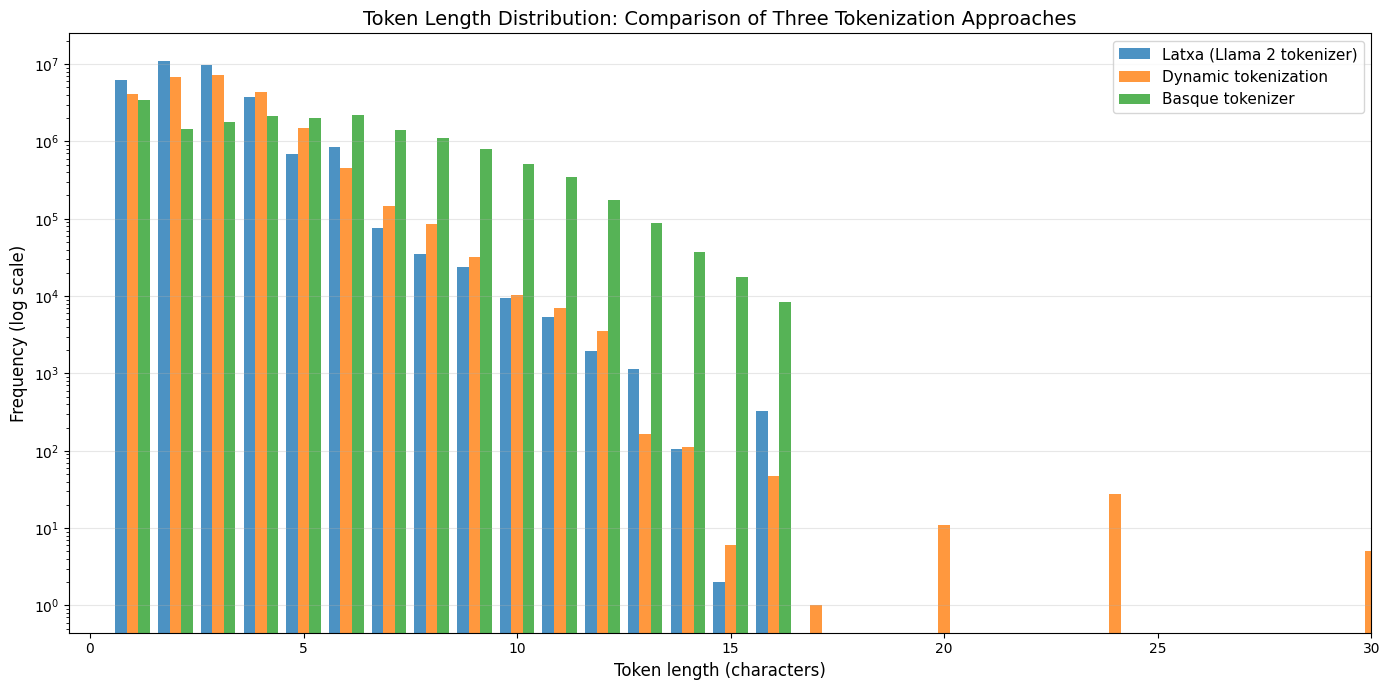

In [14]:
# ==================== Plot distributions ====================
# Prepare bins — cover all possible lengths
max_len = max(max(dist_latxa.keys()), max(dist_dynamic.keys()), max(dist_basque.keys()))
bins = np.arange(0, max_len + 2)

# Convert counters to arrays matching bins
latxa_freq = np.zeros(len(bins) - 1)
dynamic_freq = np.zeros(len(bins) - 1)
basque_freq = np.zeros(len(bins) - 1)

for length, count in dist_latxa.items():
    if length < len(latxa_freq):
        latxa_freq[length] = count

for length, count in dist_dynamic.items():
    if length < len(dynamic_freq):
        dynamic_freq[length] = count

for length, count in dist_basque.items():
    if length < len(basque_freq):
        basque_freq[length] = count

# Plot
plt.figure(figsize=(14, 7))

width = 0.27  # Width of bars (3 bars instead of 2)
x = bins[:-1]

plt.bar(x - width, latxa_freq, width=width, label="Latxa (Llama 2 tokenizer)", alpha=0.8)
plt.bar(x, dynamic_freq, width=width, label="Dynamic tokenization", alpha=0.8)
plt.bar(x + width, basque_freq, width=width, label="Basque tokenizer", alpha=0.8)

plt.yscale("log")
plt.xlabel("Token length (characters)", fontsize=12)
plt.ylabel("Frequency (log scale)", fontsize=12)
plt.title("Token Length Distribution: Comparison of Three Tokenization Approaches", fontsize=14)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3, axis='y')
plt.xlim(-0.5, min(30, max_len + 1))  # Focus on reasonable range
plt.tight_layout()
plt.savefig("token_length_comparison.png", dpi=300, bbox_inches='tight')
plt.show()

In [15]:
# ==================== Summary Statistics ====================
def get_stats(distribution):
    total_tokens = sum(distribution.values())
    weighted_sum = sum(length * count for length, count in distribution.items())
    mean_length = weighted_sum / total_tokens if total_tokens > 0 else 0
    
    # Calculate median
    cumsum = 0
    sorted_items = sorted(distribution.items())
    median_length = 0
    for length, count in sorted_items:
        cumsum += count
        if cumsum >= total_tokens / 2:
            median_length = length
            break
    
    return {
        'total_tokens': total_tokens,
        'mean_length': mean_length,
        'median_length': median_length,
        'max_length': max(distribution.keys())
    }

print("\n" + "="*60)
print("SUMMARY STATISTICS")
print("="*60)

stats_latxa = get_stats(dist_latxa)
stats_dynamic = get_stats(dist_dynamic)
stats_basque = get_stats(dist_basque)

print(f"\nLatxa (Llama 2 tokenizer):")
print(f"  Total tokens: {stats_latxa['total_tokens']:,}")
print(f"  Mean length: {stats_latxa['mean_length']:.2f} chars")
print(f"  Median length: {stats_latxa['median_length']} chars")
print(f"  Max length: {stats_latxa['max_length']} chars")

print(f"\nDynamic tokenization:")
print(f"  Total tokens: {stats_dynamic['total_tokens']:,}")
print(f"  Mean length: {stats_dynamic['mean_length']:.2f} chars")
print(f"  Median length: {stats_dynamic['median_length']} chars")
print(f"  Max length: {stats_dynamic['max_length']} chars")

print(f"\nBasque tokenizer:")
print(f"  Total tokens: {stats_basque['total_tokens']:,}")
print(f"  Mean length: {stats_basque['mean_length']:.2f} chars")
print(f"  Median length: {stats_basque['median_length']} chars")
print(f"  Max length: {stats_basque['max_length']} chars")

print("\n" + "="*60)
print("COMPARISON")
print("="*60)

# Calculate compression (fewer tokens = better)
print(f"\nToken count (lower is better):")
print(f"  Latxa: {stats_latxa['total_tokens']:,} (baseline)")
print(f"  Dynamic: {stats_dynamic['total_tokens']:,} ({100*(stats_dynamic['total_tokens']/stats_latxa['total_tokens']-1):+.1f}%)")
print(f"  Basque: {stats_basque['total_tokens']:,} ({100*(stats_basque['total_tokens']/stats_latxa['total_tokens']-1):+.1f}%)")

print(f"\nAverage token length (higher = less fragmentation):")
print(f"  Latxa: {stats_latxa['mean_length']:.2f} chars (baseline)")
print(f"  Dynamic: {stats_dynamic['mean_length']:.2f} chars ({100*(stats_dynamic['mean_length']/stats_latxa['mean_length']-1):+.1f}%)")
print(f"  Basque: {stats_basque['mean_length']:.2f} chars ({100*(stats_basque['mean_length']/stats_latxa['mean_length']-1):+.1f}%)")


SUMMARY STATISTICS

Latxa (Llama 2 tokenizer):
  Total tokens: 32,580,950
  Mean length: 2.54 chars
  Median length: 2 chars
  Max length: 16 chars

Dynamic tokenization:
  Total tokens: 24,663,719
  Mean length: 2.79 chars
  Median length: 3 chars
  Max length: 96 chars

Basque tokenizer:
  Total tokens: 17,568,957
  Mean length: 4.71 chars
  Median length: 4 chars
  Max length: 16 chars

COMPARISON

Token count (lower is better):
  Latxa: 32,580,950 (baseline)
  Dynamic: 24,663,719 (-24.3%)
  Basque: 17,568,957 (-46.1%)

Average token length (higher = less fragmentation):
  Latxa: 2.54 chars (baseline)
  Dynamic: 2.79 chars (+10.1%)
  Basque: 4.71 chars (+85.5%)


In [16]:
def average_tokens_per_word(sentences, token_lists):
    total_words = 0
    total_tokens = 0

    for sent, toks in zip(sentences, token_lists):
        words = sent.split()
        total_words += len(words)
        total_tokens += len(toks)

    return total_tokens / total_words

sentences = ds_euscrawl['train']['text'][:50000]
avg_tokens_initial = average_tokens_per_word(sentences, all_initial_tokens)
avg_tokens_dynamic = average_tokens_per_word(sentences, all_dynamic_tokens)
print(f"Initial average tokens per word: {avg_tokens_initial:.2f}")
print(f"Dynamic average tokens per word: {avg_tokens_dynamic:.2f}")

Initial average tokens per word: 3.20
Dynamic average tokens per word: 2.42


In [17]:
def word_coverage_dynamic(sentences, all_dynamic_tokens):
    total = 0
    single = 0
    total_sent = 0
    words = []
    for sent in sentences:
        words = sent.split()
        total += len(words)
        total_sent += 1
        # Get corresponding dynamic tokens
        dyn_toks = all_dynamic_tokens[total_sent - 1]
        # Reconstruct words from dynamic tokens
        reconstructed_words = []
        current_word = ""
        for tok in dyn_toks:
            if tok.startswith("Ġ"):  # assuming Ġ indicates a new word
                if current_word:
                    reconstructed_words.append(current_word)
                current_word = tok[1:]  # remove Ġ
            else:
                current_word += tok
        if current_word:
            reconstructed_words.append(current_word)
        # Check coverage
        for word in words:
            if word in reconstructed_words:
                single += 1
    return {"total": total, "single": single}
    

coverage_dynamic = word_coverage_dynamic(sentences[:10000], all_dynamic_tokens[:10000])
print(f"Initial tokenizer coverage: 7.59%")
print(f"Dynamic tokenizer coverage: {(coverage_dynamic['single']/coverage_dynamic['total'])*100:.2f}%")

Initial tokenizer coverage: 7.59%
Dynamic tokenizer coverage: 83.85%
